## Data Wrangling Project
### 3. UAP Analysis
Travis Letsch

In [1]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import re
import scipy.stats as stats
from scipy.stats import pearsonr
from scipy.stats import ttest_ind
from pandas.tseries.frequencies import infer_freq
from sklearn.neighbors import BallTree
from textblob import TextBlob
from wordcloud import WordCloud, STOPWORDS
from collections import Counter

<br>

## Overview
This is the third notebook in the set of three notebooks for this project. This notebook uses the nuforc_complete.csv file produced in the second notebook to analyze the data. The analysis includes sections examining the spatial proximity, population, and time series relationships associated with UAP sightings, as well as sighting characteristics and text analytics for sighting summaries.

<br>

#### Import nuforc_complete and the nuclear_plant_data files to begin the analysis

In [2]:
# Import the nuforc_complete CSV file as a DataFrame
nuforc_complete = pd.read_csv("nuforc_complete.csv", encoding="utf-8", sep=",")

# Ensure the leading zero in fips_combined is retained after importing
nuforc_complete["county_fips"] = nuforc_complete["county_fips"].astype(str).str.zfill(5)

display(nuforc_complete)

,year,date_time,summary,shape,city,state,county,sighting_lat,sighting_lon,county_fips,population,plant_name,plant_latitude,plant_longitude,plant_in_county,county_sightings,sightings_per_100k
0,2023,2023-01-31 19:49:00,Saw trailblazer that moves very rapid and move...,Fireball,gothenburg,NE,Dawson,40.9242,-100.1540,31047,24460.0,NaN,NaN,NaN,0,1,4.088307
1,2023,2023-01-31 19:15:00,Fast spherical orange light,Circle,sulphur springs,IN,Henry,39.9991,-85.4392,18065,48887.0,NaN,NaN,NaN,0,1,2.045534
2,2023,2023-01-31 18:38:00,Image of these UFO's were capture with Nikon D...,Light,el granada,CA,San Mateo,37.5134,-122.4657,06081,733949.0,NaN,NaN,NaN,0,4,0.544997
3,2023,2023-01-31 14:30:00,Working outside with two dozen others looked u...,Circle,layton,UT,Davis,41.0770,-111.9620,49011,374645.0,NaN,NaN,NaN,0,5,1.334597
4,2023,2023-01-30 21:15:00,Unexplained movement of one object and 40 or s...,Circle,richmond,VA,Richmond,37.5295,-77.4756,51760,230804.0,NaN,NaN,NaN,0,4,1.733072
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9113,2025,2025-12-02 17:52:00,I walked outside to let my dog out and looked ...,Light,bartlesville,OK,Washington,36.7365,-95.9456,40147,54037.0,NaN,NaN,NaN,0,2,3.701168
9114,2025,2025-12-02 04:15:00,A minimum of three lights that were alternatel...,Unknown,cimarron,KS,Gray,37.8097,-100.3453,20069,5652.0,NaN,NaN,NaN,0,1,17.692852
9115,2025,2025-12-01 22:00:00,Using night vision & FLIR; captured black tria...,Triangle,brewerton,NY,Onondaga,43.2345,-76.1410,36067,466584.0,NaN,NaN,NaN,0,3,0.642971
9116,2025,2025-12-01 21:00:00,Two pilots observed three aircraft,Light,jamestown,NY,Chautauqua,42.0976,-79.2367,36013,124126.0,NaN,NaN,NaN,0,1,0.805633


<br>

In [3]:
# Import the nuclear plant data separately to calculate distances for question 1
plant_coords_df = pd.read_csv("nuclear_plant_data.csv", encoding="utf-8", sep=",")

plant_coords_df.head()

,plant_name,plant_latitude,plant_longitude,county_fips
0,Turkey Point,25.4356,-80.3308,12086
1,St Lucie,27.3486,-80.2464,12111
2,South Texas Project,28.7950,-96.0481,48321
3,Waterford 3,29.9953,-90.4716,22089
4,River Bend,30.7570,-91.3327,22125


<br>

## 1. Are UAP sightings spatially associated with nuclear plants?

#### Use the Haversine formula and a vectorized approach with sklearn to calculate distances

In [4]:
# Convert to radians and create variables to store sets of latitudes and longitudes
uap_coords = np.radians(nuforc_complete[["sighting_lat", "sighting_lon"]])
plant_coords = np.radians(plant_coords_df[["plant_latitude", "plant_longitude"]])

In [5]:
# Build a tree from the nuclear plant coordinates 
tree = BallTree(plant_coords, metric="haversine")

In [6]:
# Using the tree, identify the plant closest to the UAP sighting
distances, _ = tree.query(uap_coords, k=1)

In [7]:
# Convert to km by multiplying by 6,371 (radius of the Earth)
nuforc_complete["plant_distance_km"] = distances.flatten() * 6371

<br>

In [8]:
# Create bins for different distance intervals in the plant_distance_km column
bins=[0, 50, 100, 200, 500, np.inf]
labels = ["0-50", "50-100", "100-200", "200-500", "500+"]

nuforc_complete["distance_band"] = pd.cut(nuforc_complete["plant_distance_km"], bins=bins, labels=labels, include_lowest=True)

# Check output
nuforc_complete.head()

,year,date_time,summary,shape,city,state,county,sighting_lat,sighting_lon,county_fips,population,plant_name,plant_latitude,plant_longitude,plant_in_county,county_sightings,sightings_per_100k,plant_distance_km,distance_band
0,2023,2023-01-31 19:49:00,Saw trailblazer that moves very rapid and move...,Fireball,gothenburg,NE,Dawson,40.9242,-100.1540,31047,24460.0,NaN,NaN,NaN,0,1,4.088307,385.825255,200-500
1,2023,2023-01-31 19:15:00,Fast spherical orange light,Circle,sulphur springs,IN,Henry,39.9991,-85.4392,18065,48887.0,NaN,NaN,NaN,0,1,2.045534,239.230675,200-500
2,2023,2023-01-31 18:38:00,Image of these UFO's were capture with Nikon D...,Light,el granada,CA,San Mateo,37.5134,-122.4657,06081,733949.0,NaN,NaN,NaN,0,4,0.544997,293.762040,200-500
3,2023,2023-01-31 14:30:00,Working outside with two dozen others looked u...,Circle,layton,UT,Davis,41.0770,-111.9620,49011,374645.0,NaN,NaN,NaN,0,5,1.334597,841.958602,500+
4,2023,2023-01-30 21:15:00,Unexplained movement of one object and 40 or s...,Circle,richmond,VA,Richmond,37.5295,-77.4756,51760,230804.0,NaN,NaN,NaN,0,4,1.733072,65.125953,50-100


<br>

In [9]:
# Check the bin distribution before performing analysis
band_counts = (nuforc_complete["distance_band"].value_counts().sort_index())

band_count_df = pd.DataFrame(band_counts.items(), columns=["band", "frequency"])

display(band_count_df)

,band,frequency
0,0-50,1094
1,50-100,1867
2,100-200,2256
3,200-500,3064
4,500+,837


<br>

In [10]:
nuforc_complete["plant_distance_km"].describe()

count    9118.000000
mean      233.379854
std       285.297103
min         2.232062
25%        79.019882
50%       166.627024
75%       280.967705
max      4003.820544
Name: plant_distance_km, dtype: float64

<br>

#### Create a bar plot of the sightings by distance

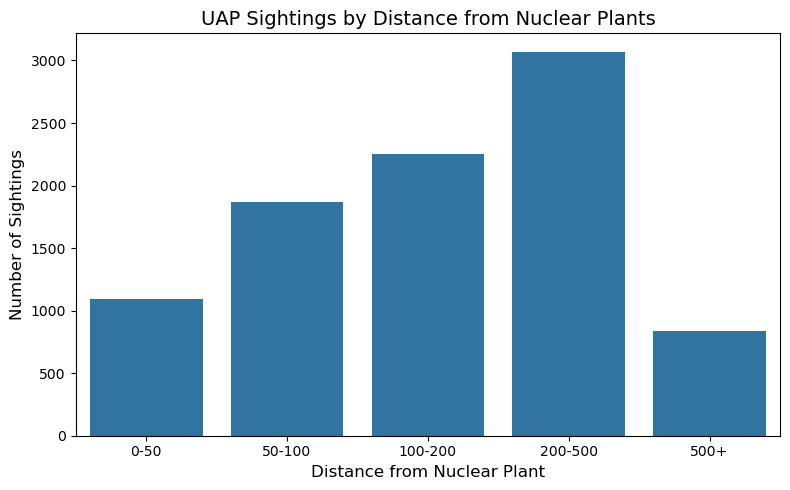

In [11]:
# Create a bar plot for distance bands
plt.figure(figsize=(8, 5))
sns.barplot(data=band_count_df, x="band", y="frequency", dodge=False, color="tab:blue", legend=False)
plt.title("UAP Sightings by Distance from Nuclear Plants", fontsize=14)
plt.xlabel("Distance from Nuclear Plant", fontsize=12)
plt.ylabel("Number of Sightings", fontsize=12)
plt.tight_layout()
plt.savefig("UAP_sightings_distance.png", dpi=300, bbox_inches="tight")
plt.show()

<br>

In [12]:
# Calculate the percentage of sightings in each band 
band_count_df["frequency_pct"] = band_percent = band_count_df["frequency"] / band_count_df["frequency"].sum()

print(band_count_df)

      band  frequency  frequency_pct
0     0-50       1094       0.119982
1   50-100       1867       0.204760
2  100-200       2256       0.247423
3  200-500       3064       0.336039
4     500+        837       0.091796


<br>

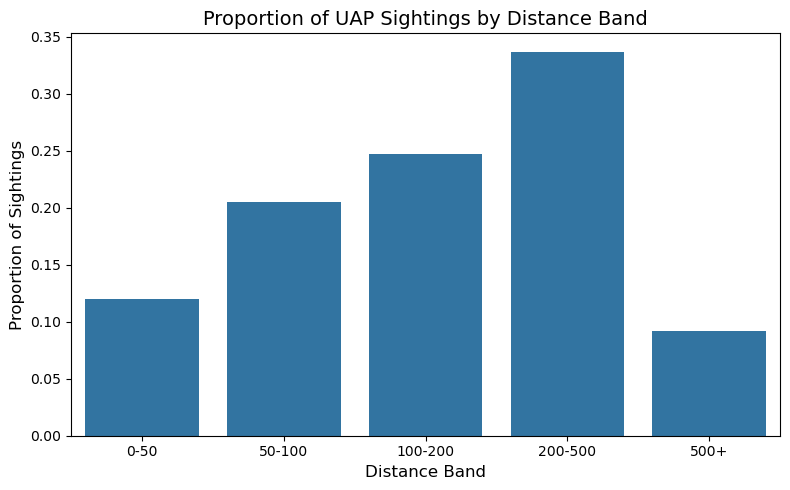

In [13]:
# Create a bar plot for distance band frequency_pct
plt.figure(figsize=(8, 5))
sns.barplot(data=band_count_df, x="band", y="frequency_pct", dodge=False, color="tab:blue", legend=False)
plt.title("Proportion of UAP Sightings by Distance Band", fontsize=14)
plt.xlabel("Distance Band", fontsize=12)
plt.ylabel("Proportion of Sightings", fontsize=12)
plt.tight_layout()
plt.savefig("UAP_sightings_distance_proportion.png", dpi=300, bbox_inches="tight")
plt.show()

<br>

#### Correlation Testing Between sightings_per_100k and plant_distance_km

In [14]:
# Calculate Pearson Correlation
pearson_corr = nuforc_complete["sightings_per_100k"].corr(nuforc_complete["plant_distance_km"], method="pearson")

# Display the result
print(f"Pearson Correlation: {pearson_corr:.4f}")

# Interpretation
if abs(pearson_corr) < 0.3:
    print("Interpretation: No or weak linear correlation.")
elif 0.3 <= abs(pearson_corr) < 0.7:
    print("Interpretation: Moderate linear correlation.")
else:
    print("Interpretation: Strong linear correlation.")

Pearson Correlation: 0.1119
Interpretation: No or weak linear correlation.


<br>

In [15]:
# Setup the Pearson Correlation Test 
corr_stat, p_value = pearsonr(nuforc_complete["sightings_per_100k"], nuforc_complete["plant_distance_km"])

# Display the correlation statistic and p-value
print(f"Pearson Correlation Coefficient: {corr_stat:.4f}")
print(f"P-value: {p_value:.4f}")

# Interpretation based on p-value
alpha = 0.05  # significance level

if p_value > alpha:
    print("Fail to reject H0: No significant correlation (correlation = 0).")
else:
    print("Reject H0: Significant correlation exists (correlation != 0).")

Pearson Correlation Coefficient: 0.1119
P-value: 0.0000
Reject H0: Significant correlation exists (correlation != 0).


<br>

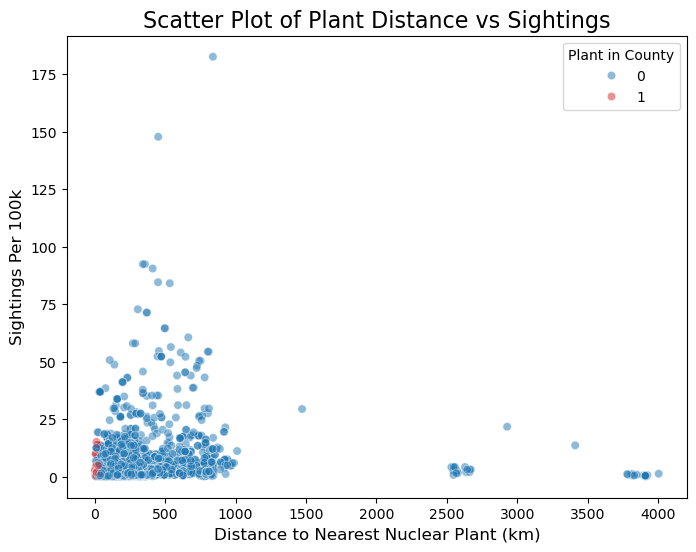

In [16]:
# Create a scatterplot of sightings_per_100k and plant_distance_km
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x="plant_distance_km", 
    y="sightings_per_100k",
    hue="plant_in_county",
    data=nuforc_complete, 
    palette={0: "tab:blue", 1: "tab:red"},
    alpha= 0.5)

# Axis labels and title
#plt.xscale("log")
plt.xlabel("Distance to Nearest Nuclear Plant (km)", fontsize=12)
plt.ylabel("Sightings Per 100k", fontsize=12)
plt.title("Scatter Plot of Plant Distance vs Sightings", fontsize=16)
plt.legend(title="Plant in County")

# Display the plot
plt.savefig("distance_sighting_scatter.png", dpi=300, bbox_inches="tight")
plt.show()

<br>

## 2. Do counties with nuclear plants have higher UAP sightings?

In [17]:
# Create variables for counties with and without plants
county_plant_population = nuforc_complete[["county_fips", "county", "population", "plant_in_county", "year"]]

plant_population = county_plant_population[(county_plant_population["plant_in_county"] == 1) & (county_plant_population["year"] == 2025)]
no_plant_population = county_plant_population[(county_plant_population["plant_in_county"] == 0) & (county_plant_population["year"] == 2025)]

display(no_plant_population)

,county_fips,county,population,plant_in_county,year
6258,12115,Sarasota,479958.0,0,2025
6259,48347,Nacogdoches,66035.0,0,2025
6260,06073,San Diego,3282248.0,0,2025
6261,21117,Kenton,175779.0,0,2025
6262,39095,Lucas,423347.0,0,2025
...,...,...,...,...,...
9113,40147,Washington,54037.0,0,2025
9114,20069,Gray,5652.0,0,2025
9115,36067,Onondaga,466584.0,0,2025
9116,36013,Chautauqua,124126.0,0,2025


<br>

In [18]:
# Calculate population means
plant_population_mean = plant_population["population"].mean()
no_plant_population_mean = no_plant_population["population"].mean()

print(round(plant_population_mean))
print(round(no_plant_population_mean))

2039367
810195


<br>

In [19]:
# Calculate Pearson Correlation between population and county_sightings
pearson_corr = nuforc_complete["population"].corr(nuforc_complete["county_sightings"], method="pearson")

# Display the result
print(f"Pearson Correlation: {pearson_corr:.4f}")

# Interpretation
if abs(pearson_corr) < 0.3:
    print("Interpretation: No or weak linear correlation.")
elif 0.3 <= abs(pearson_corr) < 0.7:
    print("Interpretation: Moderate linear correlation.")
else:
    print("Interpretation: Strong linear correlation.")

Pearson Correlation: 0.8620
Interpretation: Strong linear correlation.


<br>

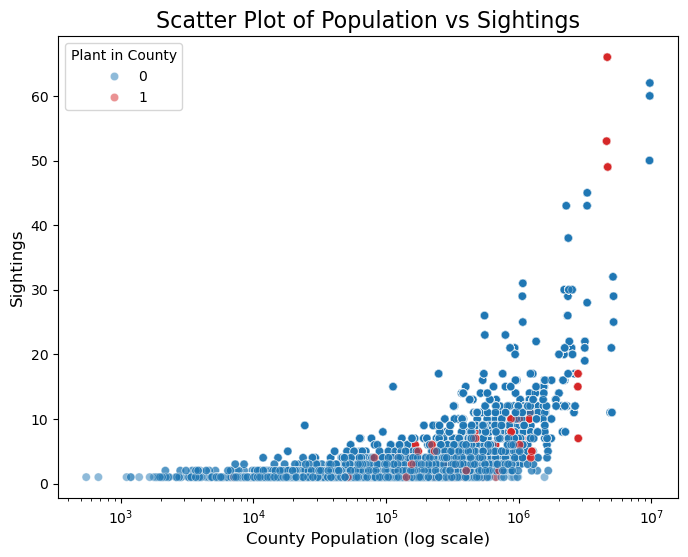

In [20]:
# Create a scatterplot data 
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x="population", 
    y="county_sightings",
    hue="plant_in_county",
    data=nuforc_complete, 
    palette={0: "tab:blue", 1: "tab:red"},
    alpha= 0.5)

# Axis labels and title
plt.xscale("log")
plt.xlabel("County Population (log scale)", fontsize=12)
plt.ylabel("Sightings", fontsize=12)
plt.title("Scatter Plot of Population vs Sightings", fontsize=16)
plt.legend(title="Plant in County")

# Display the plot
plt.savefig("population_sightings_scatter.png", dpi=300, bbox_inches="tight")
plt.show()

<br>

In [21]:
# Create a variable to store data from nuforc_complete
county_counts = nuforc_complete[["county_fips", "county", "state", "population", "county_sightings", "sightings_per_100k", "plant_in_county", "year"]]

county_counts.head()

,county_fips,county,state,population,county_sightings,sightings_per_100k,plant_in_county,year
0,31047,Dawson,NE,24460.0,1,4.088307,0,2023
1,18065,Henry,IN,48887.0,1,2.045534,0,2023
2,06081,San Mateo,CA,733949.0,4,0.544997,0,2023
3,49011,Davis,UT,374645.0,5,1.334597,0,2023
4,51760,Richmond,VA,230804.0,4,1.733072,0,2023


<br>

In [22]:
# Set the minimum population value to 50000 to avoid inflated values and extreme outliers (1 sighting in a population of 500 for example)
county_counts = county_counts[county_counts["population"] > 50000]

# Remove duplicates for multiple sightings per county 
unique_county_100k = county_counts.drop_duplicates(subset="county_fips")

# Sort the DataFrame by sightings_per_100k in descending order
unique_county_100k = unique_county_100k.sort_values("sightings_per_100k", ascending=False)

# Store the top 5 counties in a variable
top_5_counties = unique_county_100k.head()

top_5_counties.to_csv("top_5_counties_100k.csv", index=False)

display(top_5_counties)

,county_fips,county,state,population,county_sightings,sightings_per_100k,plant_in_county,year
253,53015,Cowlitz,WA,112866.0,15,13.290096,0,2023
131,04007,Gila,AZ,54040.0,6,11.102887,0,2023
1561,49021,Iron,UT,64306.0,7,10.885454,0,2023
1403,53009,Clallam,WA,77543.0,7,9.027249,0,2023
686,34009,Cape May,NJ,94577.0,8,8.458716,0,2023


<br>

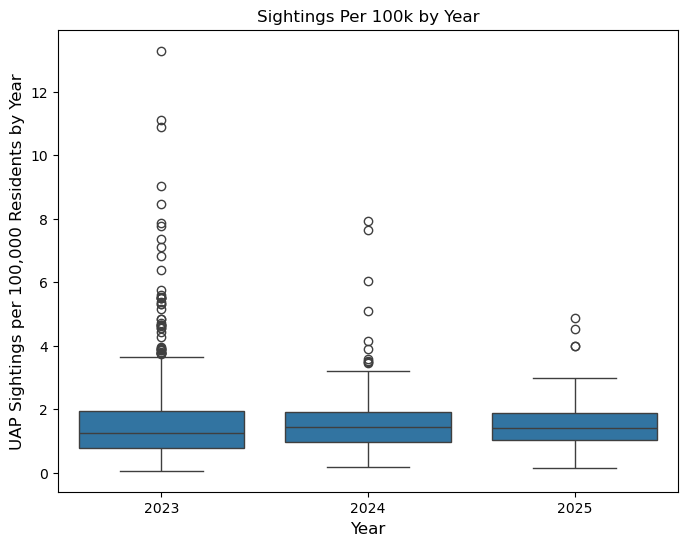

In [ ]:
# Create a boxplot for sightings_per_100k by year 
# Plot size
plt.figure(figsize=(8, 6))
sns.boxplot(
    data = unique_county_100k,
    x="year", color="tab:blue",
    y="sightings_per_100k")

# add title and labels
plt.title("Sightings Per 100k by Year")
plt.xlabel("Year", fontsize=12)
plt.ylabel("UAP Sightings per 100,000 Residents by Year", fontsize=12)
plt.savefig("Sightings_100k_year_box.png", dpi=300, bbox_inches="tight")
plt.show()

<br>

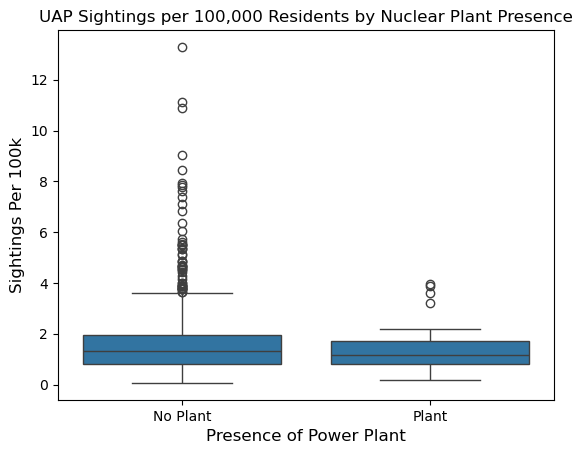

In [24]:
sns.boxplot(
    data=unique_county_100k,
    x="plant_in_county",
    y="sightings_per_100k"
)

plt.xticks([0, 1], ["No Plant", "Plant"])
plt.xlabel("Presence of Power Plant", fontsize=12)
plt.ylabel("Sightings Per 100k", fontsize=12)
plt.title("UAP Sightings per 100,000 Residents by Nuclear Plant Presence")
plt.savefig("Sightings_100k_year_plants.png", dpi=300, bbox_inches="tight")
plt.show()

<br>

#### Conduct a Welch's T-Test

In [25]:
# Split data

plant = unique_county_100k[unique_county_100k["plant_in_county"] == 1]["sightings_per_100k"]
no_plant = unique_county_100k[unique_county_100k["plant_in_county"] == 0]["sightings_per_100k"]

# perform Welch's t-test (default for unequal variances)
t_stat, p_value = ttest_ind(plant, no_plant, equal_var=False)

# display the results
print(f"T-Statistic: {t_stat:.4f}")
print(f"P-Value: {p_value:.4f}")

# interpretation
alpha = 0.05  # Significance level
if p_value < alpha:
    print("Reject H0: The average sightings are significantly different between counties with power plants and those without.")
else:
    print("Fail to reject H0: No significant difference in average sightings between counties with power plants and those without.")

T-Statistic: -1.5489
P-Value: 0.1284
Fail to reject H0: No significant difference in average sightings between counties with power plants and those without.


<br>

#### Check summary statistics for each population

In [26]:
print("Counties with plants:")
plant.describe()

Counties with plants:


count    39.000000
mean      1.384123
std       0.930164
min       0.183600
25%       0.811214
50%       1.151904
75%       1.721623
max       3.952101
Name: sightings_per_100k, dtype: float64

<br>

In [27]:
print("Counties without plants:")
no_plant.describe()

Counties without plants:


count    896.000000
mean       1.624926
std        1.333604
min        0.063864
25%        0.828310
50%        1.302936
75%        1.942244
max       13.290096
Name: sightings_per_100k, dtype: float64

<br>

## 3. How Have UAP Sightings Changed Over Time?

#### Aggregate and plot sightings by month and year

In [28]:
# Convert the date_time column to datetime and set it as the index
nuforc_complete["date_time"] = pd.to_datetime(nuforc_complete["date_time"])
nuforc_complete.set_index("date_time", inplace=True)

In [29]:
# Create variables for the month and year
nuforc_complete["year"] = nuforc_complete.index.year
nuforc_complete["month"] = nuforc_complete.index.month

# Create variables for each year
sightings_2023 = nuforc_complete[nuforc_complete["year"] == 2023].groupby("month").size()
sightings_2024 = nuforc_complete[nuforc_complete["year"] == 2024].groupby("month").size()
sightings_2025 = nuforc_complete[nuforc_complete["year"] == 2025].groupby("month").size()

# Ensure each month is represented in the output
months = range(1, 13)
sightings_2023 = sightings_2023.reindex(months, fill_value=0)
sightings_2024 = sightings_2024.reindex(months, fill_value=0)
sightings_2025 = sightings_2025.reindex(months, fill_value=0)

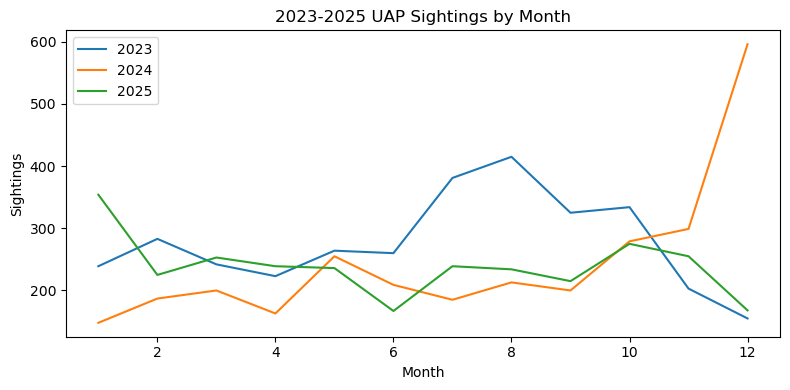

In [30]:
# Create figure
fig, ax = plt.subplots(figsize=(8, 4))

# Plot each year in a different color
plt.plot(months, sightings_2023, color="tab:blue", label="2023") 
plt.plot(months, sightings_2024, color="tab:orange", label="2024") 
plt.plot(months, sightings_2025, color="tab:green", label="2025") 

# Titles and labels
plt.title("2023-2025 UAP Sightings by Month")
plt.xlabel("Month")
plt.ylabel("Sightings")
ax.legend(loc="upper left")

# layout
fig.tight_layout()
plt.savefig("uap_sightings_year_stacked.png", dpi=300, bbox_inches="tight")
plt.show()

<br>

#### Continuous plot

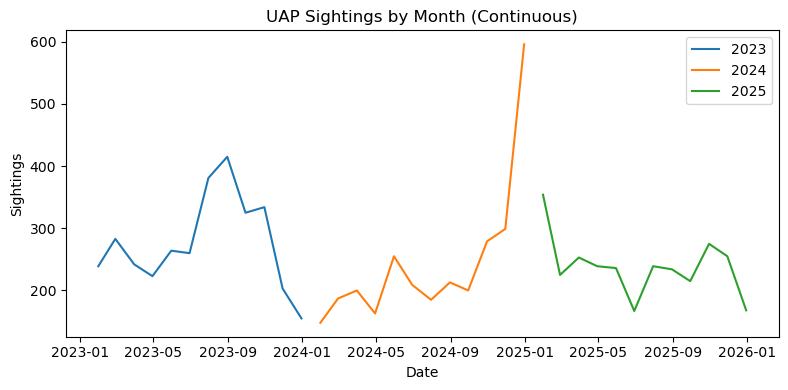

In [31]:
# Filter each year but keeping the datetime index
data_2023 = nuforc_complete[nuforc_complete["year"] == 2023].resample("ME").size()
data_2024 = nuforc_complete[nuforc_complete["year"] == 2024].resample("ME").size()
data_2025 = nuforc_complete[nuforc_complete["year"] == 2025].resample("ME").size()

fig, ax = plt.subplots(figsize=(8, 4))

# Plot each year in a different color
plt.plot(data_2023.index, data_2023.values, label="2023", color="tab:blue")
plt.plot(data_2024.index, data_2024.values, label="2024", color="tab:orange")
plt.plot(data_2025.index, data_2025.values, label="2025", color="tab:green")

# Title and labels
plt.title("UAP Sightings by Month (Continuous)")
plt.xlabel("Date")
plt.ylabel("Sightings")

ax.legend()

fig.tight_layout()
plt.savefig("uap_sightings_year_cont.png", dpi=300, bbox_inches="tight")
plt.show()

<br>

#### Summary statistics by year

In [32]:
print("2023:")
data_2023.describe()

2023:


count     12.000000
mean     277.000000
std       74.986059
min      155.000000
25%      235.000000
50%      262.000000
75%      327.250000
max      415.000000
dtype: float64

<br>

In [33]:
print("2024:")
data_2024.describe()

2024:


count     12.000000
mean     244.500000
std      119.406487
min      148.000000
25%      186.500000
50%      204.500000
75%      261.000000
max      596.000000
dtype: float64

<br>

In [34]:
print("2025:")
data_2025.describe()

2025:


count     12.000000
mean     238.333333
std       48.615997
min      167.000000
25%      222.500000
50%      237.500000
75%      253.500000
max      354.000000
dtype: float64

<br>

## 4. Characteristics of Sightings

#### Create a pie plot to display the proportions of the 5 most frequently observed shapes

In [35]:
# Calculate the frequency of shapes for UAP sightings
sighting_shapes = pd.DataFrame(nuforc_complete["shape"].value_counts().sort_index())
sighting_shapes = sighting_shapes.sort_values("count", ascending=False)

print(f"Number of unique shapes: {len(sighting_shapes)}")
display(sighting_shapes)

Number of unique shapes: 24


,count
shape,
Orb,1470
Light,1236
Circle,1047
Triangle,647
Unknown,535
Changing,521
Other,510
Sphere,385
Disk,364


<br>

In [36]:
# Create a list of values to use in a pie chart
shape_counts = nuforc_complete["shape"].value_counts().sort_values(ascending=False) 
top_5_shapes = shape_counts.head()

print(top_5_shapes)

shape
Orb         1470
Light       1236
Circle      1047
Triangle     647
Unknown      535
Name: count, dtype: int64


<br>

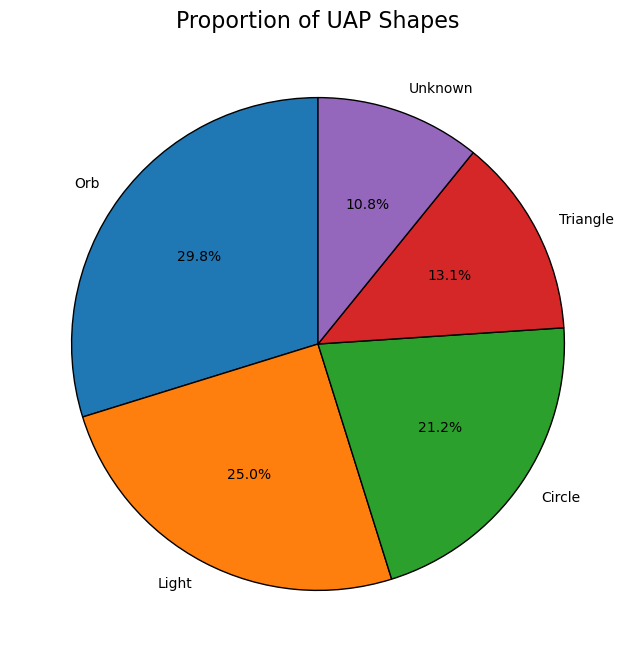

In [37]:
# Create a pie chart of the top 5 shapes 

plt.figure(figsize=(8, 8))
plt.pie(
    top_5_shapes, 
    labels=["Orb", "Light", "Circle", "Triangle", "Unknown"], 
    autopct="%1.1f%%", 
    startangle=90, 
    colors=["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple"],
    wedgeprops={"edgecolor": "black"}
)

# Add title
plt.title("Proportion of UAP Shapes", fontsize=16)

# Display the pie chart
plt.savefig("uap_shape_pie.png", dpi=300, bbox_inches="tight")
plt.show()

<br>

#### Create a frequency plot and word cloud to analyze the sighting summaries

In [38]:
# Function to preprocess text
def preprocess_text(text):
    if not isinstance(text, str):  # Check if the input is not a string
        return ""  # Return an empty string for non-string values
    text = text.lower()  # Convert to lowercase
    text = re.sub(r'http\S+', '', text)  # Remove URLs using re.sub
    text = re.sub(r'[^\w\s]', '', text)  # Remove special characters
    return text.strip()  # Remove leading and trailing whitespaces

In [39]:
# Define the function to remove stopwords and words with less than 5 letters
def filtered_text(text):
    words = text.lower().split()

    filtered_text = [
        word for word in words
        if word not in STOPWORDS and len(word) >=5]
    return " ".join(filtered_text)

In [40]:
# Apply the preprocess_text function to the summary column
nuforc_copy = pd.DataFrame(nuforc_complete)
nuforc_copy["cleaned_text"] = nuforc_copy["summary"].apply(preprocess_text)

# Apply the filtered_text function to the cleaned_text column
nuforc_copy["cleaned_text"] = nuforc_copy["cleaned_text"].apply(filtered_text)

# drop irrelevant columns for text analysis
nuforc_copy = nuforc_copy[["cleaned_text"]]

display(nuforc_copy)

,cleaned_text
date_time,
2023-01-31 19:49:00,trailblazer moves rapid moved sparkling behind...
2023-01-31 19:15:00,spherical orange light
2023-01-31 18:38:00,image capture nikon never personally objects d...
2023-01-31 14:30:00,working outside dozen others looked object
2023-01-30 21:15:00,unexplained movement object objects
...,...
2025-12-02 17:52:00,walked outside looked thinking light blurry mo...
2025-12-02 04:15:00,minimum three lights alternately bright point ...
2025-12-01 22:00:00,using night vision captured black triangle craft


<br>

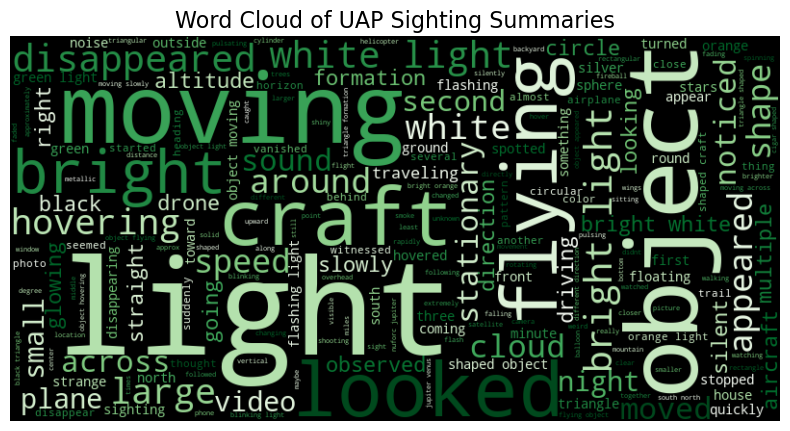

In [41]:
# Combine the text for the word cloud
all_sighting_summary = ' '.join(nuforc_copy["cleaned_text"])

# Generate the Word Cloud
wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='black',
    colormap='Greens',
).generate(all_sighting_summary)

# display the Word Cloud
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud of UAP Sighting Summaries", fontsize=16)
plt.savefig("uap_summary_cloud", dpi=300, bbox_inches="tight")
plt.show()

<br>

In [42]:
# Separate all summaries into individual words
summary_words = [word for word in all_sighting_summary.split() if word not in STOPWORDS]

# Use the counter to count the frequency of each word in lyrics_words
summary_word_counts = Counter(summary_words)

In [43]:
# Convert summary_word_counts into a DataFrame and sort by frequency
summary_count_df = pd.DataFrame(summary_word_counts.items(), columns=["word", "frequency"])

summary_count_df = summary_count_df.sort_values("frequency", ascending=False)

display(summary_count_df)

,word,frequency
9,light,1890
57,lights,1855
23,object,1470
63,moving,1420
36,bright,1333
...,...,...
3056,chesapeake,1
3057,shake,1
3058,deafening,1
3061,union,1


<br>

In [44]:
# Create a variable to store the top 10 most frequently used words
summary_top10 = summary_count_df.head(10)

display(summary_top10)

,word,frequency
9,light,1890
57,lights,1855
23,object,1470
63,moving,1420
36,bright,1333
109,white,1102
75,flying,734
39,craft,710
22,looked,543
94,shaped,502


<br>

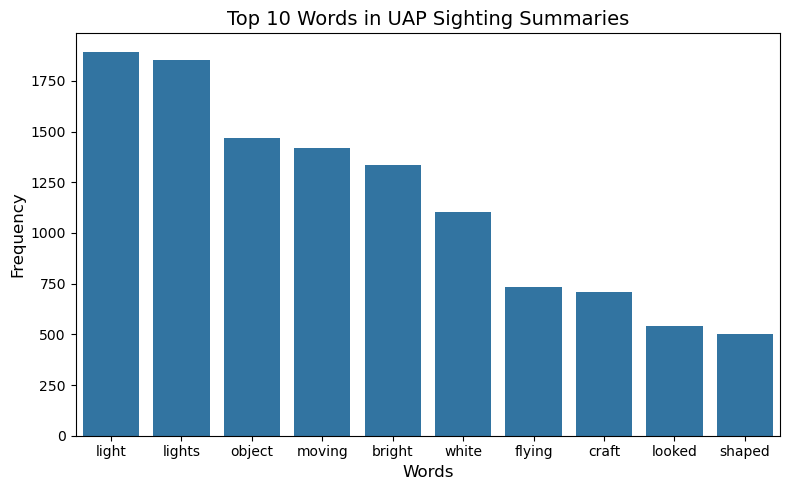

In [45]:
# Create a bar chart of the top 15 words
plt.figure(figsize=(8, 5))
sns.barplot(data=summary_top10, x="word", y="frequency", dodge=False, color="tab:blue", legend=False)
plt.title("Top 10 Words in UAP Sighting Summaries", fontsize=14)
plt.xlabel("Words", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.tight_layout()
plt.savefig("uap_summary_words.png", dpi=300, bbox_inches="tight")
plt.show()